# Data science for suppportability
### Load libraries and files contents into new dataframes ( *_df* )

In [71]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="darkgrid", palette="rainbow")
%matplotlib inline

import methods

# https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

ai4i2020_df = pd.read_csv("data/ai4i2020.csv")
    

### Check if files were loaded correctly

In [72]:
ai4i2020_df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [40]:
ai4i2020_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [73]:
renamed_df = ai4i2020_df.rename(columns={
    'Air temperature [K]': 'air_temp_k',
    'Process temperature [K]': 'process_temp_k',
    'Rotational speed [rpm]': 'speed_rpm',
    'Torque [Nm]': 'torque_nm',
    'Tool wear [min]': 'tool_wear_min',
    'Machine failure': 'failures',
    'TWF': 'tool_wear_f',
    'HDF': 'heat_diss_f',
    'PWF': 'power_f',
    'OSF': 'overstrain_f',
    'RNF': 'random_f',
})


### A function to analyse outliers

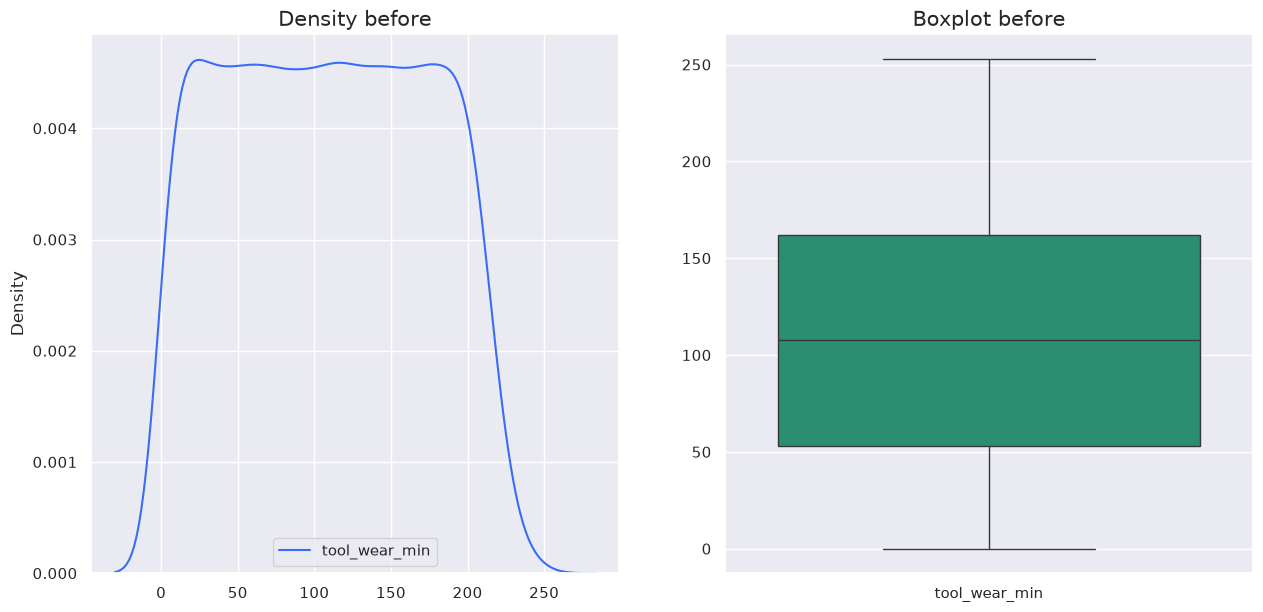

In [74]:

#column = ["air_temp_k"]
#column = ["process_temp_k"]
#column = ["speed_rpm"] # has outliers
#column = ["torque_nm"] # has outliers
column = ["tool_wear_min"]
methods.plot_outliers("before", renamed_df, column, plt, sns)


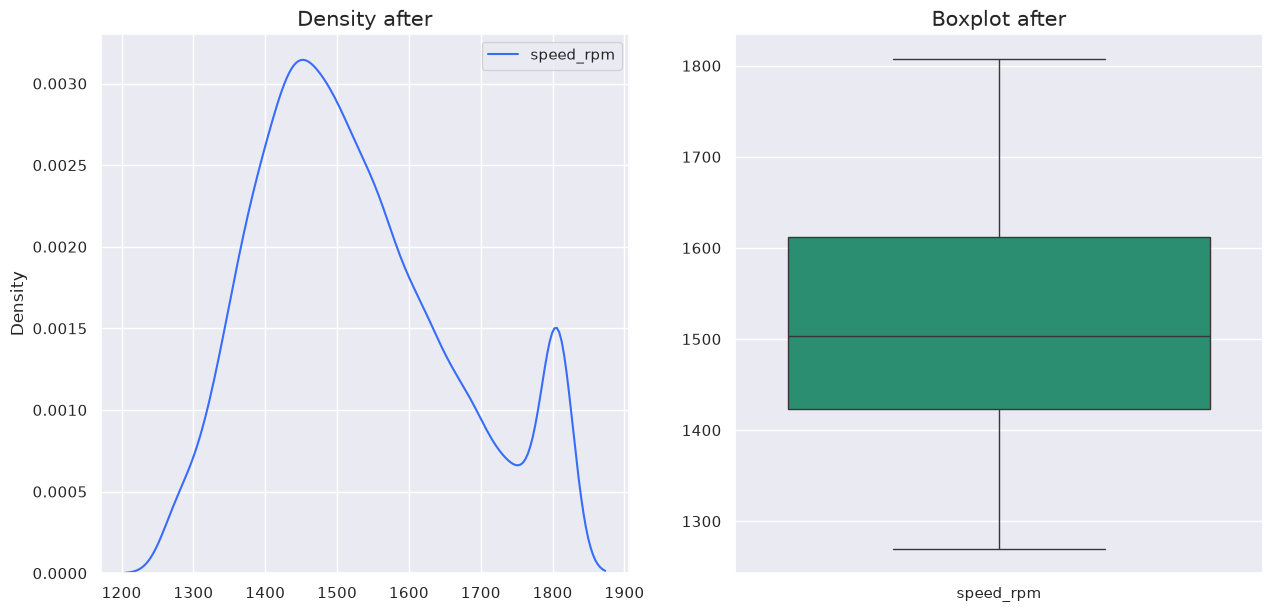

In [75]:

columns = ["speed_rpm"] # has outliers

# pass method='STD' in case of a normal distribution
# pass treatment='remove' to remove the record with outlier
renamed_treat_df = methods.treat_outliers(np, renamed_df, columns, method='STD')

# Reuses the physical variable built in Lesson 1: P = torque x angular velocity.
renamed_treat_df["mec_power_w"] = (
    renamed_treat_df["torque_nm"] * renamed_treat_df["speed_rpm"] * 2 * np.pi / 60
)

methods.plot_outliers("after", renamed_treat_df, columns, plt, sns)


## The machine failure consists of five independent failure modes:

**1. Tool Wear Failure (tool_wear_f):** the tool will be replaced or fail at a randomly selected tool wear time between 200 and 240 mins (120 times in our dataset). At this point in time, the tool is replaced 69 times, and fails 51 times (randomly assigned).

**2. Heat Dissipation Failure (heat_diss_f):** heat dissipation causes a process failure, if the difference between air- and process temperature is below 8.6 K and the tool rotational speed is below 1380 rpm. This is the case for 115 data points.

**3. Power Failure (power_f):** the product of torque and rotational speed (in rad/s) equals the power required for the process. If this power is below 3500 W or above 9000 W, the process fails, which is the case 95 times in our dataset.

**4. Overstrain Failure (overstrain_f):** if the product of tool wear and torque exceeds 11,000 min Nm for the L product variant (12,000 M, 13,000 H), the process fails due to overstrain. This is true for 98 datapoints.

**5. Random Failures (random_f):** each process has a chance of 0.1% to fail regardless of its process parameters. This is the case for only 5 datapoints, less than could be expected for 10,000 datapoints in our dataset.

aset.

In [76]:
renamed_treat_df['failures'].value_counts()

failures
0    9661
1     339
Name: count, dtype: int64

In [77]:
tool_wear_failure = renamed_treat_df['tool_wear_f'].value_counts()
tool_wear_failure

tool_wear_f
0    9954
1      46
Name: count, dtype: int64

In [78]:
heat_diss_failure=renamed_treat_df['heat_diss_f'].value_counts()
heat_diss_failure

heat_diss_f
0    9885
1     115
Name: count, dtype: int64

In [79]:
power_failure=renamed_treat_df['power_f'].value_counts()
power_failure

power_f
0    9905
1      95
Name: count, dtype: int64

In [80]:
overstrain_failure=renamed_treat_df['overstrain_f'].value_counts()
overstrain_failure

overstrain_f
0    9902
1      98
Name: count, dtype: int64

In [81]:
random_failure=renamed_treat_df['random_f'].value_counts()
random_failure

random_f
0    9981
1      19
Name: count, dtype: int64

In [82]:
heat_diss_failure+random_failure+overstrain_failure+power_failure+tool_wear_failure

heat_diss_f
0    49627
1      373
Name: count, dtype: int64

In [83]:
type=renamed_treat_df['Type'].value_counts()
type
# Low, Medium, High

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [84]:
# !pipx inject jupyterlab lightgbm

In [85]:
import lightgbm as lgb

# LightGBM is a gradient boosting framework that uses tree based learning algorithm.
# LightGBM, like all gradient boosting methods for classification, essentially combines decision trees and logistic regression.

# ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [86]:
renamed_treat_df.head()

,UDI,Product ID,Type,air_temp_k,process_temp_k,speed_rpm,torque_nm,tool_wear_min,failures,tool_wear_f,heat_diss_f,power_f,overstrain_f,random_f,mec_power_w
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0,6951.590560
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0,6826.722724
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0,7749.387543
3,4,L47183,L,298.2,308.6,1433.0,39.5,7,0,0,0,0,0,0,5927.504659
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0,5897.816608


In [87]:
features = ["air_temp_k", "process_temp_k", "speed_rpm", "torque_nm", "tool_wear_min", "mec_power_w"]

# Declare feature vector
X = renamed_treat_df[features]

# 	Machine failure	ToolWear	HeatDiss	Power	Overstrain	Random

# Declare target variable
y = renamed_treat_df['failures']
# y = renamed_treat_df['ToolWear']  # tool wear
#y = renamed_treat_df['HeatDiss'] # heat dissipation
#y = renamed_treat_df['Power'] # power failure
#y = renamed_treat_df['Overstrain'] # overstrain or excessive torque

# split the dataset into the training set and test set
# IMPORTANT: Stratify by Type to maintain L/M/H distribution (60%/30%/10%) in both train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=renamed_treat_df['Type'])

# Verify stratification worked correctly
print("Original Type distribution:")
print(renamed_treat_df['Type'].value_counts(normalize=True).sort_index())
print("\nTraining set Type distribution:")
print(renamed_treat_df.loc[X_train.index, 'Type'].value_counts(normalize=True).sort_index())
print("\nTest set Type distribution:")
print(renamed_treat_df.loc[X_test.index, 'Type'].value_counts(normalize=True).sort_index())

Original Type distribution:
Type
H    0.1003
L    0.6000
M    0.2997
Name: proportion, dtype: float64

Training set Type distribution:
Type
H    0.100286
L    0.600000
M    0.299714
Name: proportion, dtype: float64

Test set Type distribution:
Type
H    0.100333
L    0.600000
M    0.299667
Name: proportion, dtype: float64


In [89]:
# !pipx inject jupyterlab scikit-learn

In [90]:
import numpy as np
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, classification_report)

neg, pos = np.bincount(y_train)[[0, 1]]

clf = lgb.LGBMClassifier(
    learning_rate=0.05,
    n_estimators=500,
    num_leaves=15,
    max_bin=125,
    min_child_samples=10,
    scale_pos_weight=neg / pos,   # ≈ 29
    importance_type='gain',
    random_state=42,
    verbose=-1,                   # silences the log
)
clf.fit(X_train, y_train)

proba = clf.predict_proba(X_test)[:, 1]
print("PR-AUC :", average_precision_score(y_test, proba))
print("ROC-AUC:", roc_auc_score(y_test, proba))

PR-AUC : 0.7594572643066261
ROC-AUC: 0.960013051161198


In [91]:
# Obtain gain feature importance
gain_importance = clf.feature_importances_

# Display feature importance with feature names
feature_names = X.columns

gain_importance_df = pd.DataFrame({'Feature': feature_names, 'Gain': gain_importance})
print(gain_importance_df.sort_values(by='Gain', ascending=False))

          Feature          Gain
3       torque_nm  49122.286617
2       speed_rpm  47750.465326
4   tool_wear_min  41100.495133
5     mec_power_w  16531.148638
0      air_temp_k  13681.361243
1  process_temp_k   7903.375695


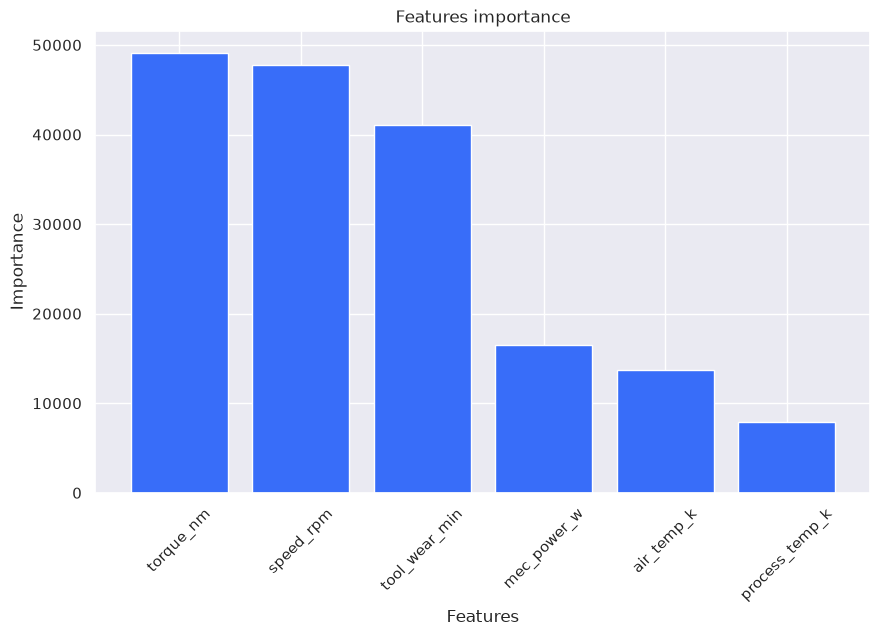

In [92]:

methods.plot_feature_importance(gain_importance, feature_names, "Features importance", plt, pd)

In [93]:
# predict the results
y_pred=clf.predict(X_test)

In [94]:
# view accuracy
from sklearn.metrics import accuracy_score
print('LightGBM Model accuracy score: {0:0.4f}'.format(accuracy_score(y_test, y_pred)))

LightGBM Model accuracy score: 0.9800


In [95]:
y_proba = clf.predict_proba(X_test)[:, 1]

from sklearn.metrics import roc_auc_score

print('LightGBM ROC AUC score: {0:0.4f}'.format(roc_auc_score(y_test, y_proba)))

LightGBM ROC AUC score: 0.9600


In [96]:
y_pred_train = clf.predict(X_train)

print('Training-set accuracy score: {0:0.4f}'. format(accuracy_score(y_train, y_pred_train)))


Training-set accuracy score: 0.9999


In [97]:
# print the scores on training and test set

print('Training set score: {:.4f}'.format(clf.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(clf.score(X_test, y_test)))

Training set score: 0.9999
Test set score: 0.9800


In [98]:
# Confusion matrix
# In scikit-learn, rows are actual classes and columns are predicted classes.
# For labels [0, 1], the layout is:
# [[TN, FP],
#  [FN, TP]]

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print('Confusion matrix [[TN, FP], [FN, TP]]\n')
print(cm)
print(f'\nTrue Negatives  (TN) = {tn}')
print(f'False Positives (FP) = {fp}')
print(f'False Negatives (FN) = {fn}')
print(f'True Positives  (TP) = {tp}')


Confusion matrix [[TN, FP], [FN, TP]]

[[2859   34]
 [  26   81]]

True Negatives  (TN) = 2859
False Positives (FP) = 34
False Negatives (FN) = 26
True Positives  (TP) = 81


Text(0.5, 1.0, 'Confusion matrix')

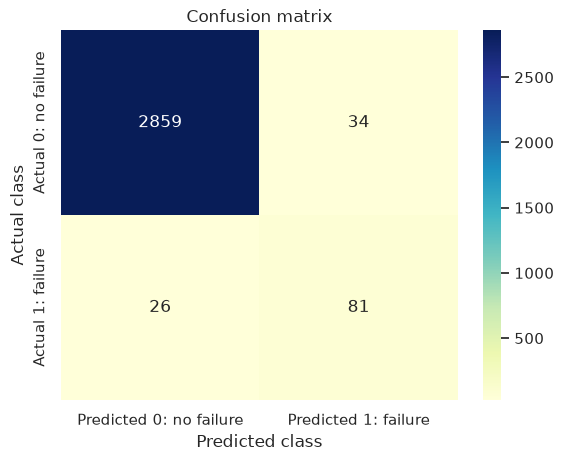

In [99]:
# Visualize confusion matrix with seaborn heatmap
cm_matrix = pd.DataFrame(
    data=cm,
    columns=['Predicted 0: no failure', 'Predicted 1: failure'],
    index=['Actual 0: no failure', 'Actual 1: failure']
)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.title('Confusion matrix')


In [100]:
#Classification Metrices

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2893
           1       0.70      0.76      0.73       107

    accuracy                           0.98      3000
   macro avg       0.85      0.87      0.86      3000
weighted avg       0.98      0.98      0.98      3000



In [101]:
# Safety-Critical Metrics Analysis
from sklearn.metrics import recall_score, precision_score, fbeta_score, f1_score

# Use the explicit confusion-matrix decomposition to avoid swapping TN/TP or FP/FN.
tn, fp, fn, tp = cm.ravel()

# Calculate key metrics
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
miss_rate = fn / (fn + tp) if (fn + tp) > 0 else 0
false_positive_rate = fp / (tn + fp) if (tn + fp) > 0 else 0
f2_score = fbeta_score(y_test, y_pred, beta=2)

# Display results
print("=" * 60)
print("SAFETY-CRITICAL METRICS ANALYSIS")
print("=" * 60)
print(f"\nPRIMARY SAFETY METRICS:")
print(f"   Recall (Sensitivity):        {recall:.2%}  <- Detection Rate")
print(f"   Miss Rate (1 - Recall):      {miss_rate:.2%}  <- SAFETY RISK")
print(f"\nSUPPORTING METRICS:")
print(f"   Specificity:                 {specificity:.2%}  <- Safe Detection")
print(f"   False Positive Rate:         {false_positive_rate:.2%}  <- False Alarms")
print(f"   Precision:                   {precision:.2%}  <- Prediction Accuracy")
print(f"\nCOMPOSITE SCORES:")
print(f"   F1 Score (balanced):         {f1_score(y_test, y_pred):.4f}")
print(f"   F2 Score (safety-weighted):  {f2_score:.4f}  <- Preferred when recall matters")
print("=" * 60)

# Cost Analysis
cost_fn = 1_000_000  # $1M per missed failure
cost_fp = 10_000     # $10K per false alarm
fn_count = fn
fp_count = fp

total_cost = (fn_count * cost_fn) + (fp_count * cost_fp)

print(f"\nCOST ANALYSIS:")
print(f"   False Negatives: {fn_count:3d} x ${cost_fn:,} = ${fn_count * cost_fn:,}")
print(f"   False Positives: {fp_count:3d} x ${cost_fp:,}   = ${fp_count * cost_fp:,}")
print(f"   {'-' * 50}")
print(f"   Total Expected Cost:              ${total_cost:,}")
print("=" * 60)

# Safety Assessment
print(f"\nAVIATION SAFETY ASSESSMENT:")
if recall < 0.90:
    print(f"   INSUFFICIENT: {recall:.1%} detection rate is too low")
    print(f"      Target: >95% for safety-critical systems")
    print(f"      Action: Adjust decision threshold or retrain model")
elif recall < 0.95:
    print(f"   MARGINAL: {recall:.1%} detection rate is borderline")
    print(f"      Consider improvements to reach >95% target")
else:
    print(f"   ACCEPTABLE: {recall:.1%} detection rate meets safety standards")

print("=" * 60)


SAFETY-CRITICAL METRICS ANALYSIS

PRIMARY SAFETY METRICS:
   Recall (Sensitivity):        75.70%  <- Detection Rate
   Miss Rate (1 - Recall):      24.30%  <- SAFETY RISK

SUPPORTING METRICS:
   Specificity:                 98.82%  <- Safe Detection
   False Positive Rate:         1.18%  <- False Alarms
   Precision:                   70.43%  <- Prediction Accuracy

COMPOSITE SCORES:
   F1 Score (balanced):         0.7297
   F2 Score (safety-weighted):  0.7459  <- Preferred when recall matters

COST ANALYSIS:
   False Negatives:  26 x $1,000,000 = $26,000,000
   False Positives:  34 x $10,000   = $340,000
   --------------------------------------------------
   Total Expected Cost:              $26,340,000

AVIATION SAFETY ASSESSMENT:
   INSUFFICIENT: 75.7% detection rate is too low
      Target: >95% for safety-critical systems
      Action: Adjust decision threshold or retrain model


## Safety-Critical Metrics Analysis for Aviation Maintenance

For aviation applications, we must prioritize **false negative reduction** because missed failures are catastrophic. 

See **CONFUSION_MATRIX_GUIDE.md** for detailed explanation of why these metrics matter.